# TDE 03 — Construção do Baseline e Avaliação de Modelos
## Previsão de Consumo de Energia Elétrica Residencial (kWh)

**Notebook individual de:** Taliciane  
**Ênfase teórica e prática deste notebook:** Métricas da Árvore de Decisão e gráficos de erro  
**Tipo de problema:** Regressão | **Baselines:** Regressão Linear e Árvore de Decisão (`DecisionTreeRegressor`) | **Métricas:** MAE, MSE, RMSE e R²


> O projeto segue um **modelo acumulativo em escada**: cada notebook contém todas as etapas anteriores e aprofunda a etapa de seu responsável.

| Etapa | Responsável | Conteúdo | Incluída |
|---|---|---|---|
| 1 | Lia | Geração do dataset + Análise Exploratória de Dados (EDA) | neste notebook |
| 2 | Ingrid | Pré-processamento, tratamento de dados e Engenharia de Recursos |  neste notebook |
| 3 | Clara | Divisão dos dados em Treino e Teste (train_test_split) | neste notebook |
| 4 | Daniel | Baseline 1: Regressão Linear | neste notebook |
| 5 | Michel | Métricas (MAE, MSE, RMSE, R²) e análise da Regressão Linear |  neste notebook |
| 6 | Morya | Baseline 2: Árvore de Decisão para Regressão | neste notebook |
| 7 | Taliciane | Métricas da Árvore de Decisão e gráficos de erro | neste notebook |
| 8 | Wesley | Análise comparativa final, discussão crítica e conclusões | — |

**Requisitos:** Python 3.9+, `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn`.

# Etapa 1 — Geração do Dataset e Análise Exploratória (EDA)
**Responsável: Lia**

## 1.1 Contexto do problema
Queremos **prever o consumo mensal de energia elétrica de uma residência (kWh)** a partir de características da casa, da família e do clima. Como o alvo (`consumo_kwh`) é um **valor contínuo**, trata-se de um problema de **regressão supervisionada**.

Geramos os dados por simulação, com regras inspiradas na realidade (mais moradores, maior área e mais ar-condicionado → mais consumo; energia solar reduz o consumo da rede) e **defeitos propositais** (valores ausentes, duplicatas, valores impossíveis e outliers). Isso torna as etapas seguintes (pré-processamento, divisão, modelagem) realistas.

> Como os dados vêm de uma simulação com `seed` fixa, **todos os resultados são reprodutíveis**.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
TARGET = "consumo_kwh"
np.random.seed(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3})
print("Ambiente pronto.")

Ambiente pronto.


## 1.2 Geração do dataset
Variáveis simuladas:

| Variável | Descrição |
|---|---|
| `id_residencia` | identificador |
| `mes` | mês de referência (1–12) |
| `temperatura_media` | temperatura média do mês (°C), com sazonalidade |
| `num_moradores` | pessoas na residência |
| `tipo_residencia` | `casa` ou `apartamento` |
| `area_m2` | área construída |
| `renda_familiar` | renda mensal (R$) |
| `num_ar_condicionado` | aparelhos de ar-condicionado |
| `num_geladeiras` | geladeiras/freezers |
| `possui_energia_solar` | 1 se tem painel solar |
| `horas_home_office` | horas diárias de trabalho em casa |
| `idade_imovel_anos` | idade do imóvel (**variável sem efeito real** — serve para testar se os modelos a ignoram) |
| `consumo_kwh` | **alvo**: consumo mensal em kWh |

In [2]:
def gerar_dataset(n=1500, seed=SEED):
    rng = np.random.default_rng(seed)

    mes = rng.integers(1, 13, n)
    temperatura = 27 + 3 * np.sin(2 * np.pi * (mes - 4) / 12) + rng.normal(0, 1.5, n)
    moradores = np.clip(rng.poisson(2.2, n) + 1, 1, 8)
    tipo = rng.choice(["casa", "apartamento"], n, p=[0.6, 0.4])
    area = np.where(tipo == "casa", rng.normal(110, 35, n), rng.normal(65, 20, n))
    area = np.clip(area, 25, 350).round(1)
    renda = (rng.lognormal(7.9, 0.5, n) * (0.7 + area / 150)).round(0)
    ar = np.clip(rng.poisson(0.4 + renda / 6000, n), 0, 5)
    geladeiras = rng.choice([1, 2], n, p=[0.85, 0.15])
    solar = rng.binomial(1, np.clip(renda / 40000, 0.02, 0.4))
    home_office = rng.integers(0, 9, n)
    idade = rng.integers(1, 41, n).astype(float)

    # regra "verdadeira" (desconhecida para o modelo) + ruído
    efeito_ar = ar * np.maximum(temperatura - 23, 0) * 14      # relação NÃO linear (interação ar x calor)
    consumo = (35 + 0.9 * area + 22 * moradores + 28 * geladeiras
               + 6 * home_office + 3 * (temperatura - 27) + efeito_ar)
    consumo = consumo * np.where(solar == 1, 0.72, 1.0)
    consumo = consumo + rng.normal(0, 18, n)
    consumo = np.clip(consumo, 25, None).round(1)

    df = pd.DataFrame({
        "id_residencia": np.arange(1, n + 1),
        "mes": mes,
        "temperatura_media": temperatura.round(1),
        "num_moradores": moradores,
        "tipo_residencia": tipo,
        "area_m2": area,
        "renda_familiar": renda,
        "num_ar_condicionado": ar,
        "num_geladeiras": geladeiras,
        "possui_energia_solar": solar,
        "horas_home_office": home_office,
        "idade_imovel_anos": idade,
        "consumo_kwh": consumo,
    })

    # ---- defeitos propositais (realismo) ----
    for col, frac in [("renda_familiar", 0.06), ("area_m2", 0.03), ("idade_imovel_anos", 0.04)]:
        idx = rng.choice(n, int(frac * n), replace=False)
        df.loc[idx, col] = np.nan                                  # valores ausentes
    df.loc[rng.choice(n, 3, replace=False), "area_m2"] = -1        # valores impossíveis (erro de digitação)
    df.loc[rng.choice(n, 8, replace=False), "consumo_kwh"] *= 2.8  # outliers extremos (erro de medição)
    duplicadas = df.sample(8, random_state=seed)                   # linhas duplicadas
    df = pd.concat([df, duplicadas], ignore_index=True)
    return df

df_raw = gerar_dataset()
df_raw.to_csv("dataset_consumo_energia.csv", index=False)
print("Dataset gerado e salvo em 'dataset_consumo_energia.csv'")
print("Formato:", df_raw.shape)
df_raw.head()

Dataset gerado e salvo em 'dataset_consumo_energia.csv'
Formato: (1508, 13)


,id_residencia,mes,temperatura_media,num_moradores,tipo_residencia,area_m2,renda_familiar,num_ar_condicionado,num_geladeiras,possui_energia_solar,horas_home_office,idade_imovel_anos,consumo_kwh
0,1,2,24.30,6,apartamento,27.40,635.00,0,1,0,2,20.00,197.20
1,2,10,28.70,3,casa,61.10,"1,603.00",0,1,0,1,33.00,190.10
2,3,8,26.20,3,casa,128.20,"5,291.00",0,1,0,5,6.00,273.90
3,4,6,27.40,3,casa,60.50,"2,474.00",0,1,0,0,22.00,182.50
4,5,6,28.20,1,casa,132.00,"3,223.00",0,1,0,0,34.00,218.20


## 1.3 Análise Exploratória de Dados (EDA)

**Teoria.** A EDA é o primeiro contato com os dados. Seus objetivos são: (i) entender a estrutura (tipos, tamanho); (ii) detectar problemas de qualidade (nulos, duplicatas, outliers, valores impossíveis); (iii) conhecer a distribuição do alvo; (iv) levantar hipóteses sobre quais variáveis explicam o alvo (correlações, comparações por grupo). **Nada é "corrigido" aqui** — apenas diagnosticado; a correção é a Etapa 2.

### 1.3.1 Estrutura e tipos

In [3]:
print("Linhas x colunas:", df_raw.shape)
print()
df_raw.info()

Linhas x colunas: (1508, 13)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1508 entries, 0 to 1507
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_residencia         1508 non-null   int64  
 1   mes                   1508 non-null   int64  
 2   temperatura_media     1508 non-null   float64
 3   num_moradores         1508 non-null   int64  
 4   tipo_residencia       1508 non-null   object 
 5   area_m2               1464 non-null   float64
 6   renda_familiar        1418 non-null   float64
 7   num_ar_condicionado   1508 non-null   int64  
 8   num_geladeiras        1508 non-null   int64  
 9   possui_energia_solar  1508 non-null   int64  
 10  horas_home_office     1508 non-null   int64  
 11  idade_imovel_anos     1448 non-null   float64
 12  consumo_kwh           1508 non-null   float64
dtypes: float64(5), int64(7), object(1)
memory usage: 153.3+ KB


### 1.3.2 Estatísticas descritivas

In [4]:
display(df_raw.describe().T)
print("\nVariável categórica:")
display(df_raw["tipo_residencia"].value_counts(normalize=True).rename("proporção").to_frame())

,count,mean,std,min,25%,50%,75%,max
id_residencia,"1,508.00",750.79,432.72,1.00,377.75,750.50,"1,124.25","1,500.00"
mes,"1,508.00",6.58,3.47,1.00,4.00,7.00,10.00,12.00
temperatura_media,"1,508.00",26.92,2.60,20.00,24.90,26.90,28.90,34.40
num_moradores,"1,508.00",3.16,1.48,1.00,2.00,3.00,4.00,8.00
area_m2,"1,464.00",90.50,37.36,-1.00,62.08,85.65,115.58,213.60
renda_familiar,"1,418.00","3,953.26","2,295.17",635.00,"2,410.00","3,344.50","4,841.50","21,711.00"
num_ar_condicionado,"1,508.00",1.08,1.08,0.00,0.00,1.00,2.00,5.00
num_geladeiras,"1,508.00",1.16,0.36,1.00,1.00,1.00,1.00,2.00
possui_energia_solar,"1,508.00",0.10,0.29,0.00,0.00,0.00,0.00,1.00
horas_home_office,"1,508.00",3.99,2.59,0.00,2.00,4.00,6.00,8.00



Variável categórica:


,proporção
tipo_residencia,
casa,0.59
apartamento,0.41


**O que observar:** compare `mean` com `50%` (mediana) — grande diferença indica assimetria; observe `min`/`max` (`area_m2` com mínimo negativo é impossível; o `max` de `consumo_kwh` está muito acima do `75%`).

### 1.3.3 Qualidade dos dados

,nulos,% nulos
area_m2,44,2.92
renda_familiar,90,5.97
idade_imovel_anos,60,3.98


Linhas duplicadas: 8
Áreas <= 0 (impossíveis): 3


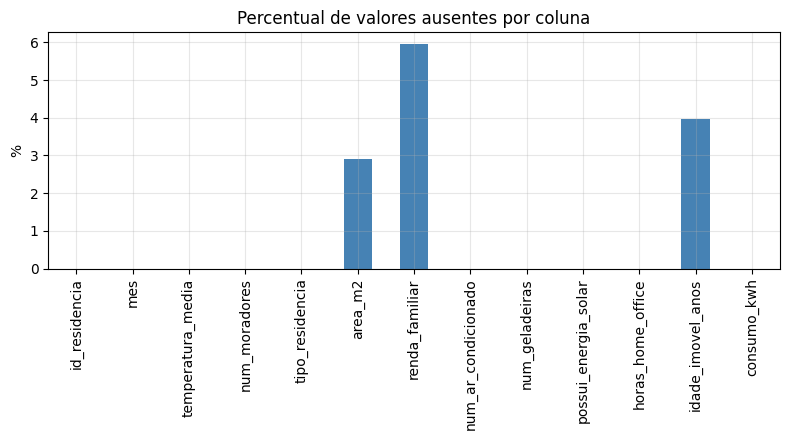

In [5]:
qualidade = pd.DataFrame({
    "nulos": df_raw.isna().sum(),
    "% nulos": (df_raw.isna().mean() * 100).round(2),
})
display(qualidade[qualidade["nulos"] > 0])
print("Linhas duplicadas:", df_raw.duplicated().sum())
print("Áreas <= 0 (impossíveis):", (df_raw["area_m2"] <= 0).sum())

fig, ax = plt.subplots()
qualidade["% nulos"].plot.bar(ax=ax, color="steelblue")
ax.set_title("Percentual de valores ausentes por coluna"); ax.set_ylabel("%")
plt.tight_layout(); plt.show()

### 1.3.4 Distribuição da variável-alvo
Entender o alvo é essencial em regressão: sua escala define o que é um "erro grande" e sua assimetria/outliers influenciam métricas como RMSE e R².

Média: 297.4 | Mediana: 278.6 | Desvio: 111.6 | Assimetria: 1.95


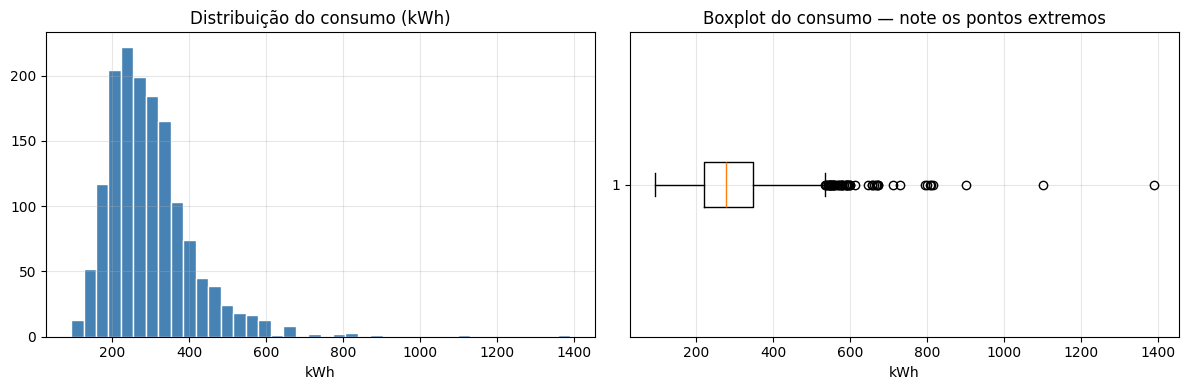

In [6]:
y_raw = df_raw[TARGET]
print(f"Média: {y_raw.mean():.1f} | Mediana: {y_raw.median():.1f} | Desvio: {y_raw.std():.1f} | Assimetria: {y_raw.skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_raw, bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Distribuição do consumo (kWh)"); axes[0].set_xlabel("kWh")
axes[1].boxplot(y_raw, vert=False)
axes[1].set_title("Boxplot do consumo — note os pontos extremos"); axes[1].set_xlabel("kWh")
plt.tight_layout(); plt.show()

### 1.3.5 Distribuição das variáveis numéricas

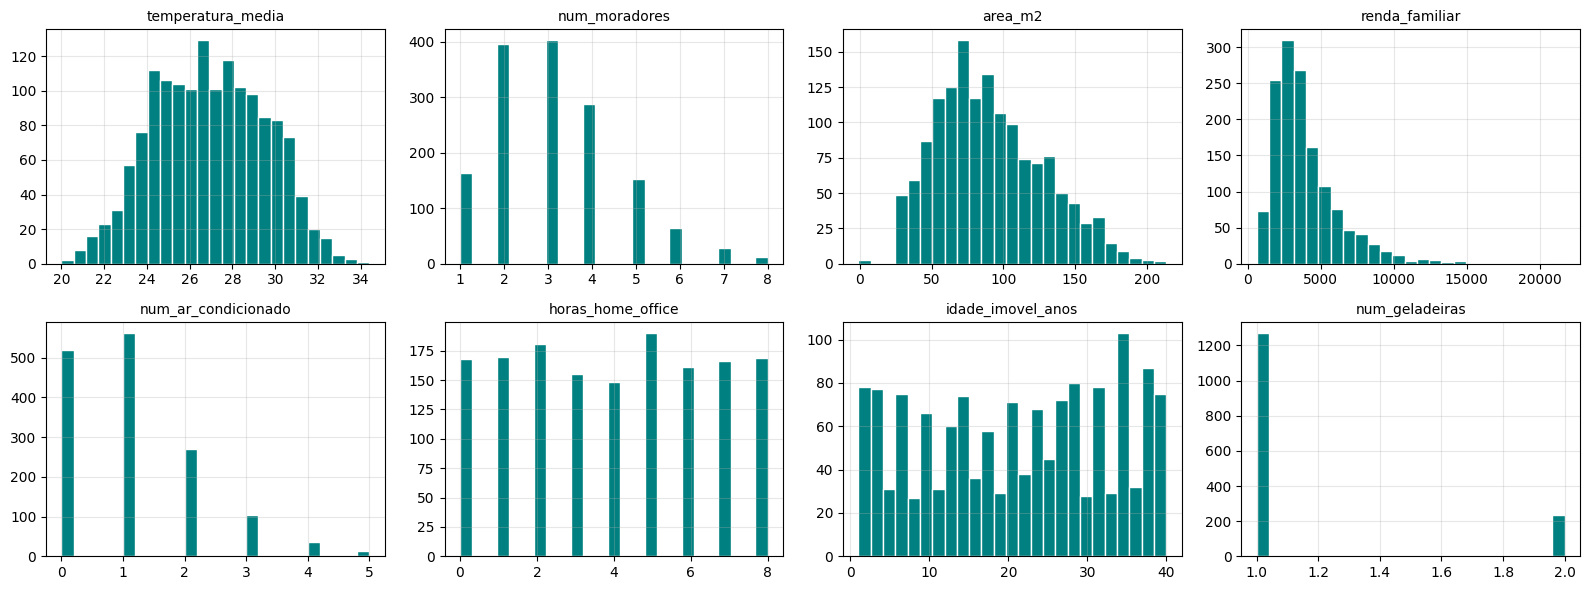

In [7]:
num_cols_eda = ["temperatura_media", "num_moradores", "area_m2", "renda_familiar",
                "num_ar_condicionado", "horas_home_office", "idade_imovel_anos", "num_geladeiras"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), num_cols_eda):
    ax.hist(df_raw[col].dropna(), bins=25, color="teal", edgecolor="white")
    ax.set_title(col, fontsize=10)
plt.tight_layout(); plt.show()

### 1.3.6 Relações com o alvo
**Correlação de Pearson** mede relação **linear** (−1 a 1). Ela não captura relações não lineares nem interações — por isso complementamos com gráficos e comparações por grupo.

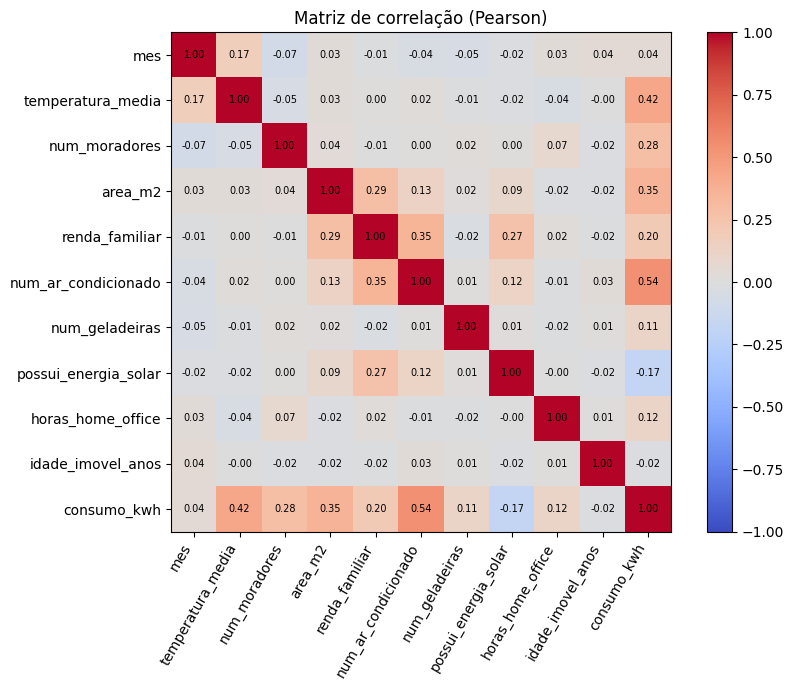

Correlação com o alvo:


,correlação
num_ar_condicionado,0.54
temperatura_media,0.42
area_m2,0.35
num_moradores,0.28
renda_familiar,0.20
horas_home_office,0.12
num_geladeiras,0.11
mes,0.04
idade_imovel_anos,-0.02
possui_energia_solar,-0.17


In [8]:
num_df = df_raw.select_dtypes(include="number").drop(columns=["id_residencia"])
corr = num_df.corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False); plt.colorbar(im); ax.set_title("Matriz de correlação (Pearson)")
plt.tight_layout(); plt.show()

print("Correlação com o alvo:")
display(corr[TARGET].drop(TARGET).sort_values(ascending=False).to_frame("correlação"))

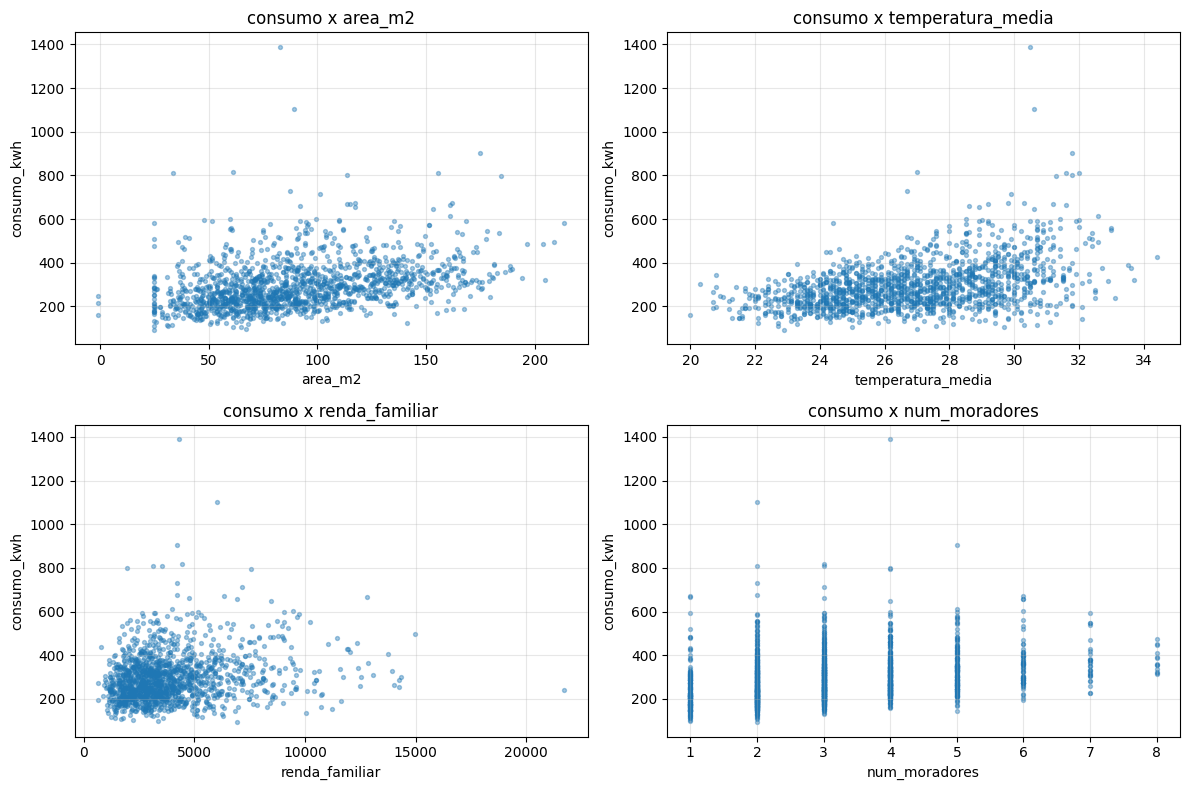

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["area_m2", "temperatura_media", "renda_familiar", "num_moradores"]):
    ax.scatter(df_raw[col], df_raw[TARGET], s=8, alpha=0.4)
    ax.set_xlabel(col); ax.set_ylabel("consumo_kwh"); ax.set_title(f"consumo x {col}")
plt.tight_layout(); plt.show()

### 1.3.7 Comparação por grupos

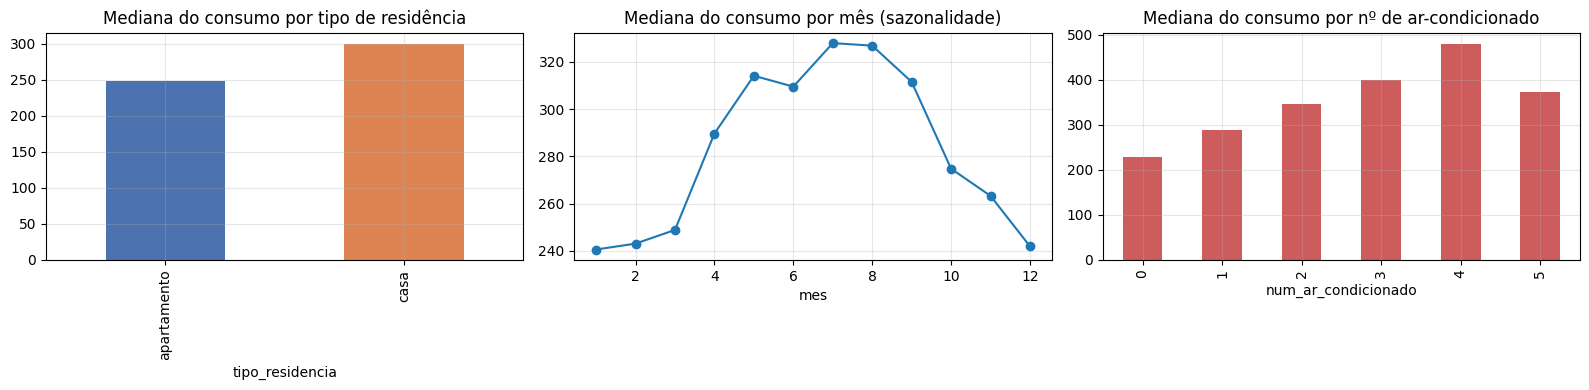

,count,mean,std,min,25%,50%,75%,max
possui_energia_solar,,,,,,,,
0,"1,363.00",303.68,110.64,111.20,227.10,285.20,350.80,"1,390.20"
1,145.00,238.47,103.91,92.80,171.20,219.90,269.20,903.00


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df_raw.groupby("tipo_residencia")[TARGET].median().plot.bar(ax=axes[0], color=["#4c72b0", "#dd8452"])
axes[0].set_title("Mediana do consumo por tipo de residência")

df_raw.groupby("mes")[TARGET].median().plot(ax=axes[1], marker="o")
axes[1].set_title("Mediana do consumo por mês (sazonalidade)")

df_raw.groupby("num_ar_condicionado")[TARGET].median().plot.bar(ax=axes[2], color="indianred")
axes[2].set_title("Mediana do consumo por nº de ar-condicionado")
plt.tight_layout(); plt.show()

display(df_raw.groupby("possui_energia_solar")[TARGET].describe())

### 1.3.8 Conclusões da EDA (insumos para as próximas etapas)
1. **Valores ausentes** em `renda_familiar`, `area_m2` e `idade_imovel_anos` → exigem imputação (Etapa 2).
2. **Duplicatas** e **áreas negativas** → erros de coleta; devem ser removidos/corrigidos.
3. **Outliers extremos** em `consumo_kwh` (muito acima do restante) → provável erro de medição; decidir tratamento.
4. `area_m2`, `num_moradores` e `num_ar_condicionado` têm relação positiva clara com o consumo; `temperatura_media` e `mes` indicam **sazonalidade**.
5. `renda_familiar` é assimétrica à direita → candidata a transformação logarítmica.
6. A relação entre ar-condicionado e temperatura sugere **não linearidade/interação** — algo que a Regressão Linear simples pode não capturar e a Árvore de Decisão pode.

# Etapa 2 — Pré-processamento, Tratamento de Dados e Engenharia de Recursos
**Responsável: Ingrid**

## 2.1 Teoria
Modelos não aprendem com "dados crus": precisam de dados **limpos, numéricos e informativos**. Esta etapa tem três frentes:

1. **Limpeza determinística** (regras que não dependem de estatísticas dos dados): remover duplicatas, tratar valores impossíveis.
2. **Engenharia de recursos (*feature engineering*)**: criar variáveis novas a partir das existentes, usando conhecimento do domínio.
3. **Transformações estatísticas** (imputação, padronização, codificação de categorias): são **aprendidas** a partir dos dados e, por isso, devem ser ajustadas **apenas no treino** para evitar **vazamento de dados (*data leakage*)**. Por isso as definimos agora como um `ColumnTransformer`, mas só o **ajustamos (`fit`) depois da divisão treino/teste** — dentro de um `Pipeline`.

In [17]:
df = df_raw.copy()

# 1) duplicatas
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

# 2) valores impossíveis -> viram NaN (serão imputados no pipeline)
n_area_neg = (df["area_m2"] <= 0).sum()
df.loc[df["area_m2"] <= 0, "area_m2"] = np.nan

# 3) outliers extremos do alvo (regra IQR com fator 3 = "outlier extremo")
q1, q3 = df[TARGET].quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 3 * iqr
n_out = (df[TARGET] > limite_sup).sum()
df_clean = df[df[TARGET] <= limite_sup].reset_index(drop=True)

print(f"Duplicatas removidas: {n_dup}")
print(f"Áreas impossíveis convertidas em NaN: {n_area_neg}")
print(f"Outliers extremos do alvo removidos (> {limite_sup:.0f} kWh): {n_out}")
print(f"Formato: {df_raw.shape} -> {df_clean.shape}")

Duplicatas removidas: 8
Áreas impossíveis convertidas em NaN: 3
Outliers extremos do alvo removidos (> 725 kWh): 9
Formato: (1508, 13) -> (1491, 13)


In [18]:
def criar_features(d):
    d = d.copy()
    d["area_por_morador"] = d["area_m2"] / d["num_moradores"]
    d["total_eletro"] = d["num_ar_condicionado"] + d["num_geladeiras"]
    d["renda_log"] = np.log1p(d["renda_familiar"])
    d["mes_sin"] = np.sin(2 * np.pi * d["mes"] / 12)
    d["mes_cos"] = np.cos(2 * np.pi * d["mes"] / 12)
    d["periodo_chuvoso"] = d["mes"].between(2, 5).astype(int)
    return d

df_fe = criar_features(df_clean)

num_features = ["temperatura_media", "num_moradores", "area_m2", "num_ar_condicionado",
                "num_geladeiras", "horas_home_office", "idade_imovel_anos",
                "area_por_morador", "total_eletro", "renda_log", "mes_sin", "mes_cos"]
cat_features = ["tipo_residencia"]
bin_features = ["possui_energia_solar", "periodo_chuvoso"]
FEATURES = num_features + cat_features + bin_features

num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_features),
    ("cat", cat_pipe, cat_features),
    ("bin", "passthrough", bin_features),
])

print(f"{len(FEATURES)} variáveis de entrada definidas.")
print("Pré-processador definido (ainda NÃO ajustado — o fit será feito só no treino).")
df_fe.head()

15 variáveis de entrada definidas.
Pré-processador definido (ainda NÃO ajustado — o fit será feito só no treino).


,id_residencia,mes,temperatura_media,num_moradores,tipo_residencia,area_m2,renda_familiar,num_ar_condicionado,num_geladeiras,possui_energia_solar,horas_home_office,idade_imovel_anos,consumo_kwh,area_por_morador,total_eletro,renda_log,mes_sin,mes_cos,periodo_chuvoso
0,1,2,24.30,6,apartamento,27.40,635.00,0,1,0,2,20.00,197.20,4.57,1,6.46,0.87,0.50,1
1,2,10,28.70,3,casa,61.10,"1,603.00",0,1,0,1,33.00,190.10,20.37,1,7.38,-0.87,0.50,0
2,3,8,26.20,3,casa,128.20,"5,291.00",0,1,0,5,6.00,273.90,42.73,1,8.57,-0.87,-0.50,0
3,4,6,27.40,3,casa,60.50,"2,474.00",0,1,0,0,22.00,182.50,20.17,1,7.81,0.00,-1.00,0
4,5,6,28.20,1,casa,132.00,"3,223.00",0,1,0,0,34.00,218.20,132.00,1,8.08,0.00,-1.00,0


## 2.2 Aprofundamento — decisões de tratamento (com evidências)

### 2.2.1 Valores ausentes: quais estratégias existem?
| Estratégia | Quando usar | Risco |
|---|---|---|
| Remover linhas | poucos nulos, aleatórios | perde dados e pode enviesar |
| Média | variável simétrica | sensível a outliers; reduz variância |
| **Mediana** | variável assimétrica/com outliers | também reduz variância |
| Moda | categóricas | pode inflar a categoria dominante |
| KNN/modelo | relações fortes entre variáveis | mais custo/complexidade |

Escolhemos **mediana** (numéricas) e **moda** (categóricas): simples, robustas e adequadas a baselines. Veja o efeito em `renda_familiar` (apenas ilustração, em uma cópia):

In [19]:
renda = df_clean[["renda_familiar"]]
comp = pd.DataFrame({
    "original (sem nulos)": renda["renda_familiar"].dropna().describe(),
    "imputada por média": pd.Series(SimpleImputer(strategy="mean").fit_transform(renda).ravel()).describe(),
    "imputada por mediana": pd.Series(SimpleImputer(strategy="median").fit_transform(renda).ravel()).describe(),
}).loc[["count", "mean", "std", "50%"]]
display(comp)
print("Nulos tratados:", df_clean["renda_familiar"].isna().sum(), "-> o desvio-padrão diminui um pouco após imputar (efeito esperado).")

,original (sem nulos),imputada por média,imputada por mediana
count,"1,401.00","1,491.00","1,491.00"
mean,"3,952.18","3,952.18","3,915.29"
std,"2,295.53","2,225.12","2,229.88"
50%,"3,341.00","3,434.00","3,341.00"


Nulos tratados: 90 -> o desvio-padrão diminui um pouco após imputar (efeito esperado).


### 2.2.2 Outliers: remover, limitar ou manter?
Removemos apenas os **extremos** (acima de Q3 + 3·IQR), pois são consistentes com erro de medição. Outliers "moderados" (entre 1,5·IQR e 3·IQR) foram **mantidos**: podem ser consumos legítimos de casas grandes. Veja o antes/depois:

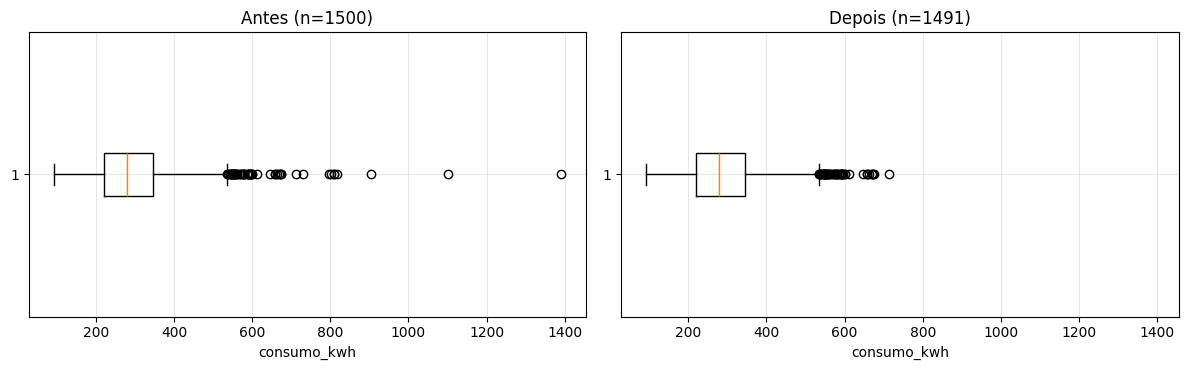

Outliers moderados mantidos: 46


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
axes[0].boxplot(df[TARGET], vert=False); axes[0].set_title(f"Antes (n={len(df)})")
axes[1].boxplot(df_clean[TARGET], vert=False); axes[1].set_title(f"Depois (n={len(df_clean)})")
for ax in axes: ax.set_xlabel("consumo_kwh")
plt.tight_layout(); plt.show()

moderados = ((df_clean[TARGET] > q3 + 1.5 * iqr)).sum()
print(f"Outliers moderados mantidos: {moderados}")

### 2.2.3 Engenharia de recursos — o que criamos e por quê
| Nova variável | Justificativa |
|---|---|
| `area_por_morador` | densidade de ocupação: casas grandes com poucos moradores se comportam diferente |
| `total_eletro` | resume a carga de equipamentos de refrigeração |
| `renda_log` | `renda` é assimétrica; o `log` aproxima de uma distribuição simétrica |
| `mes_sin`, `mes_cos` | **codificação cíclica**: dezembro (12) e janeiro (1) são vizinhos, mas numericamente distantes; seno/cosseno preservam essa circularidade |
| `periodo_chuvoso` | indicador sazonal (fev–mai) |
| `tipo_residencia` → one-hot | modelos numéricos não aceitam texto; `drop="first"` evita colinearidade perfeita (*dummy trap*) |

Veja o efeito da transformação logarítmica e as novas correlações:

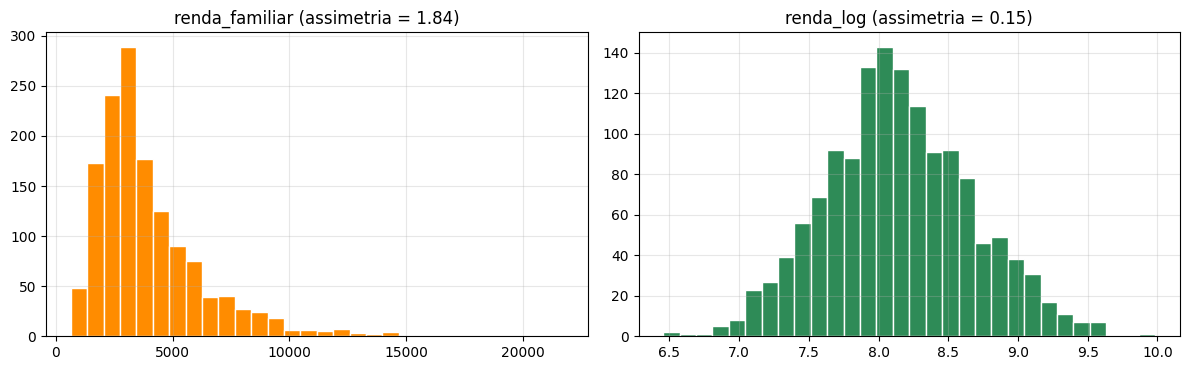

,correlação com o alvo
total_eletro,0.59
mes_cos,-0.30
renda_log,0.23
mes_sin,-0.18
periodo_chuvoso,-0.08
area_por_morador,-0.00


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(df_fe["renda_familiar"].dropna(), bins=30, color="darkorange", edgecolor="white")
axes[0].set_title(f"renda_familiar (assimetria = {df_fe['renda_familiar'].skew():.2f})")
axes[1].hist(df_fe["renda_log"].dropna(), bins=30, color="seagreen", edgecolor="white")
axes[1].set_title(f"renda_log (assimetria = {df_fe['renda_log'].skew():.2f})")
plt.tight_layout(); plt.show()

novas = ["area_por_morador", "total_eletro", "renda_log", "mes_sin", "mes_cos", "periodo_chuvoso"]
display(df_fe[novas + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("correlação com o alvo"))

### 2.2.4 Padronização (`StandardScaler`) e por que o `fit` só no treino
`z = (x − média) / desvio`. Para a **Regressão Linear**, padronizar não muda as previsões, mas torna os **coeficientes comparáveis**. Para **Árvores**, é desnecessário (mas inofensivo) — usamos o mesmo pré-processador nos dois modelos para uma comparação justa.

**Vazamento de dados:** se calculássemos médias/medianas/desvios usando *todo* o dataset, o teste "vazaria" informação para o treino e as métricas ficariam otimistas. O `Pipeline` garante que `fit` ocorra só no treino e o teste apenas receba `transform`.

### 2.2.5 Checagem final do dataset tratado

In [22]:
resumo = pd.DataFrame({
    "tipo": df_fe[FEATURES].dtypes.astype(str),
    "nulos restantes": df_fe[FEATURES].isna().sum(),
})
display(resumo)
print("Nulos ainda existem de propósito: serão imputados DENTRO do pipeline, após a divisão treino/teste.")
print("Nulos no alvo:", df_fe[TARGET].isna().sum())

,tipo,nulos restantes
temperatura_media,float64,0
num_moradores,int64,0
area_m2,float64,47
num_ar_condicionado,int64,0
num_geladeiras,int64,0
horas_home_office,int64,0
idade_imovel_anos,float64,60
area_por_morador,float64,47
total_eletro,int64,0
renda_log,float64,90


Nulos ainda existem de propósito: serão imputados DENTRO do pipeline, após a divisão treino/teste.
Nulos no alvo: 0


# Etapa 3 — Divisão em Treino e Teste (`train_test_split`)
**Responsável: Clara**

## 3.1 Teoria
O objetivo de um modelo é **generalizar**: funcionar bem em dados que nunca viu. Avaliar no mesmo dado usado para treinar mede apenas **memorização**. Por isso separamos:

* **Treino (80%)**: o modelo aprende (e o pré-processador é ajustado) aqui.
* **Teste (20%)**: guardado e usado **uma única vez**, ao final, para estimar o desempenho real.

Parâmetros importantes: `test_size` (proporção), `random_state` (reprodutibilidade) e `stratify` (preserva a distribuição de uma variável). Em regressão não se estratifica diretamente por um valor contínuo, mas é possível estratificar por **faixas (quantis) do alvo**.

In [23]:
X = df_fe[FEATURES]
y = df_fe[TARGET]

y_faixas = pd.qcut(y, q=5, labels=False, duplicates="drop")   # 5 faixas de consumo (quintis)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y_faixas
)

print(f"Treino: {X_train.shape[0]} linhas ({X_train.shape[0]/len(X):.0%})")
print(f"Teste : {X_test.shape[0]} linhas ({X_test.shape[0]/len(X):.0%})")

Treino: 1192 linhas (80%)
Teste : 299 linhas (20%)


## 3.2 Aprofundamento — verificando e entendendo a divisão

### 3.2.1 A divisão preservou a distribuição do alvo?

,Treino,Teste
count,"1,192.00",299.00
mean,294.15,292.98
std,101.06,98.18
min,92.80,111.20
25%,221.65,217.30
50%,277.10,280.40
75%,346.92,343.05
max,713.30,672.80


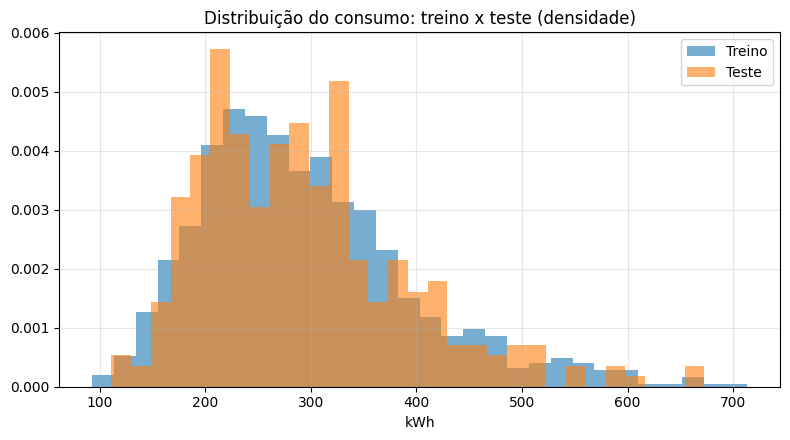

Teste de Kolmogorov-Smirnov: estatística=0.032, p-valor=0.962
p-valor alto => não há evidência de que treino e teste venham de distribuições diferentes.


In [24]:
comparacao = pd.DataFrame({"Treino": y_train.describe(), "Teste": y_test.describe()})
display(comparacao)

fig, ax = plt.subplots()
ax.hist(y_train, bins=30, alpha=0.6, density=True, label="Treino")
ax.hist(y_test, bins=30, alpha=0.6, density=True, label="Teste")
ax.set_title("Distribuição do consumo: treino x teste (densidade)"); ax.set_xlabel("kWh"); ax.legend()
plt.tight_layout(); plt.show()

ks = stats.ks_2samp(y_train, y_test)
print(f"Teste de Kolmogorov-Smirnov: estatística={ks.statistic:.3f}, p-valor={ks.pvalue:.3f}")
print("p-valor alto => não há evidência de que treino e teste venham de distribuições diferentes.")

### 3.2.2 Por que estratificar? Experimento com várias sementes
Repetimos a divisão com 20 sementes, **com e sem** estratificação, e medimos a variação da média do alvo no teste. Menor variação = divisões mais estáveis/representativas.

In [25]:
medias_sem, medias_com = [], []
for s in range(20):
    _, _, _, yt = train_test_split(X, y, test_size=0.2, random_state=s)
    medias_sem.append(yt.mean())
    _, _, _, yt = train_test_split(X, y, test_size=0.2, random_state=s, stratify=y_faixas)
    medias_com.append(yt.mean())

print(f"Desvio da média do teste SEM estratificação: {np.std(medias_sem):.2f} kWh")
print(f"Desvio da média do teste COM estratificação: {np.std(medias_com):.2f} kWh")
print(f"Média real do alvo: {y.mean():.2f} kWh")

Desvio da média do teste SEM estratificação: 4.35 kWh
Desvio da média do teste COM estratificação: 1.69 kWh
Média real do alvo: 293.91 kWh


### 3.2.3 Integridade da divisão (checagens obrigatórias)

In [26]:
assert set(X_train.index).isdisjoint(X_test.index), "Vazamento: há linhas em treino e teste!"
assert len(X_train) + len(X_test) == len(X)
print("✔ Nenhuma linha aparece nos dois conjuntos.")
print("✔ Treino + Teste = dataset completo.")

print("\nProporção de nulos (%) por conjunto:")
display(pd.DataFrame({"Treino": X_train.isna().mean() * 100, "Teste": X_test.isna().mean() * 100})
        .loc[lambda d: (d > 0).any(axis=1)])

✔ Nenhuma linha aparece nos dois conjuntos.
✔ Treino + Teste = dataset completo.

Proporção de nulos (%) por conjunto:


,Treino,Teste
area_m2,2.94,4.01
idade_imovel_anos,3.86,4.68
area_por_morador,2.94,4.01
renda_log,6.29,5.02


### 3.2.4 Validação cruzada (visão geral)
Com um único teste, a estimativa depende "da sorte" da divisão. A **validação cruzada k-fold** divide o **treino** em *k* partes e rotaciona qual delas valida. Ela será usada nas etapas seguintes para **escolher hiperparâmetros e comparar modelos sem tocar no teste**.

In [27]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
for i, (idx_tr, idx_val) in enumerate(kf.split(X_train), start=1):
    print(f"Fold {i}: treina com {len(idx_tr)} | valida com {len(idx_val)}")

Fold 1: treina com 953 | valida com 239
Fold 2: treina com 953 | valida com 239
Fold 3: treina com 954 | valida com 238
Fold 4: treina com 954 | valida com 238
Fold 5: treina com 954 | valida com 238


**Boas práticas adotadas:** `random_state` fixo; estratificação por quintis do alvo; pré-processamento ajustado só no treino; teste intocado até a avaliação final.

# Etapa 4 — Baseline 1: Regressão Linear
**Responsável: Daniel**

## 4.1 Teoria
A **Regressão Linear** modela o alvo como combinação linear das variáveis:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

Os coeficientes são estimados por **Mínimos Quadrados Ordinários (OLS)**, minimizando a soma dos quadrados dos resíduos:

$$\min_{\beta} \sum_i (y_i - \hat{y}_i)^2$$

* **Vantagens:** simples, rápida, interpretável (cada coeficiente = efeito de uma variável, mantidas as demais constantes).
* **Limitações:** assume relação **linear e aditiva**; sensível a outliers e a multicolinearidade; não captura interações automaticamente.

Por ser simples e interpretável, é o ponto de partida natural (**baseline**).

In [28]:
modelo_lr = Pipeline([
    ("prep", preprocessor),
    ("reg", LinearRegression()),
])
modelo_lr.fit(X_train, y_train)          # preprocessor + regressão ajustados SÓ no treino

y_pred_lr_train = modelo_lr.predict(X_train)
y_pred_lr_test = modelo_lr.predict(X_test)
print("Regressão Linear treinada.")

Regressão Linear treinada.


## 4.2 Aprofundamento — o que o modelo aprendeu?

### 4.2.1 Intercepto e coeficientes
Como as variáveis numéricas foram **padronizadas**, os coeficientes numéricos são comparáveis: representam a variação em kWh para **+1 desvio-padrão** da variável.

Intercepto (β0): 303.40 kWh  (previsão para a 'casa média' de referência)


,coeficiente
possui_energia_solar,-97.07
temperatura_media,42.25
num_moradores,31.19
area_m2,31.07
num_ar_condicionado,30.55
total_eletro,29.02
horas_home_office,14.92
periodo_chuvoso,2.62
renda_log,2.18
num_geladeiras,1.56


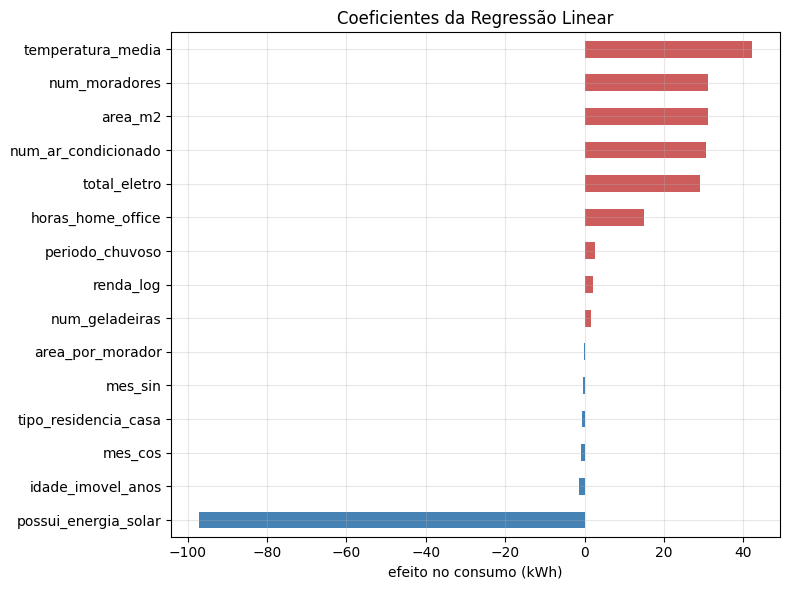

In [29]:
nomes = modelo_lr.named_steps["prep"].get_feature_names_out()
nomes = [n.split("__", 1)[1] for n in nomes]
reg = modelo_lr.named_steps["reg"]

coef_lr = pd.Series(reg.coef_, index=nomes).sort_values()
print(f"Intercepto (β0): {reg.intercept_:.2f} kWh  (previsão para a 'casa média' de referência)")
display(coef_lr.sort_values(key=abs, ascending=False).to_frame("coeficiente").head(12))

fig, ax = plt.subplots(figsize=(8, 6))
coef_lr.plot.barh(ax=ax, color=np.where(coef_lr > 0, "indianred", "steelblue"))
ax.set_title("Coeficientes da Regressão Linear"); ax.set_xlabel("efeito no consumo (kWh)")
plt.tight_layout(); plt.show()

### 4.2.2 Verificando o OLS "na unha"
A solução de mínimos quadrados é $\hat\beta = (X^\top X)^{-1} X^\top y$ (aqui via `numpy.linalg.lstsq`, mais estável). Confirmamos que o resultado coincide com o do `scikit-learn`:

In [30]:
Xt_train = modelo_lr.named_steps["prep"].transform(X_train)
Xt_train = Xt_train.toarray() if hasattr(Xt_train, "toarray") else np.asarray(Xt_train)
X_design = np.column_stack([np.ones(len(Xt_train)), Xt_train])          # coluna de 1s = intercepto

beta, *_ = np.linalg.lstsq(X_design, y_train.values, rcond=None)
print("Intercepto igual ao do sklearn? ", np.isclose(beta[0], reg.intercept_))
print("Coeficientes iguais aos do sklearn?", np.allclose(beta[1:], reg.coef_))

# previsão manual de UMA residência
i = 0
manual = beta[0] + Xt_train[i] @ beta[1:]
print(f"\nPrevisão manual (1ª linha do treino): {manual:.2f} kWh | modelo: {y_pred_lr_train[i]:.2f} kWh | real: {y_train.iloc[i]:.2f} kWh")

Intercepto igual ao do sklearn?  True
Coeficientes iguais aos do sklearn? True

Previsão manual (1ª linha do treino): 160.08 kWh | modelo: 160.08 kWh | real: 202.50 kWh


### 4.2.3 Primeiras previsões

In [31]:
amostra = pd.DataFrame({
    "real_kwh": y_test.values[:10],
    "previsto_kwh": y_pred_lr_test[:10],
})
amostra["erro"] = amostra["previsto_kwh"] - amostra["real_kwh"]
display(amostra.round(1))

,real_kwh,previsto_kwh,erro
0,462.80,413.10,-49.70
1,223.80,209.00,-14.80
2,327.70,299.10,-28.60
3,271.70,309.50,37.80
4,285.00,257.10,-27.90
5,462.30,420.90,-41.40
6,234.80,248.50,13.70
7,181.30,210.60,29.30
8,215.10,315.90,100.80
9,218.70,218.40,-0.30


### 4.2.4 Pressupostos e limitações da Regressão Linear
1. **Linearidade:** a relação entre cada variável e o alvo é reta. (Em nossos dados, o efeito do ar-condicionado depende da temperatura — uma **interação** que o modelo linear não vê.)
2. **Independência dos erros** entre observações.
3. **Homocedasticidade:** variância constante dos erros.
4. **Normalidade dos resíduos** (importante para inferência, menos para previsão).
5. **Ausência de multicolinearidade severa** (ex.: `area_m2` e `area_por_morador` são correlacionadas, o que pode inflar a instabilidade de coeficientes individuais).

A verificação desses pressupostos é feita com a análise de resíduos na Etapa 5.

# Etapa 5 — Métricas de Regressão e Análise da Regressão Linear
**Responsável: Michel**

## 5.1 Teoria das métricas
Seja $y_i$ o valor real, $\hat y_i$ a previsão e $n$ o número de observações.

| Métrica | Fórmula | Interpretação |
|---|---|---|
| **MAE** | $\frac1n\sum \lvert y_i-\hat y_i\rvert$ | erro médio absoluto, **na unidade do alvo (kWh)**; robusto a outliers |
| **MSE** | $\frac1n\sum (y_i-\hat y_i)^2$ | média dos erros ao quadrado; unidade kWh²; **pune muito erros grandes** |
| **RMSE** | $\sqrt{\text{MSE}}$ | volta à unidade do alvo; "erro típico" com peso nos erros grandes |
| **R²** | $1-\frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ | fração da variância explicada; 1 = perfeito, 0 = igual a prever a média, **pode ser negativo** |

**Relações úteis:** RMSE ≥ MAE sempre; quanto maior a diferença entre eles, mais erros grandes existem.

In [32]:
def avaliar(modelo, X_tr, y_tr, X_te, y_te, nome):
    linhas = []
    for conjunto, (Xc, yc) in {"Treino": (X_tr, y_tr), "Teste": (X_te, y_te)}.items():
        yp = modelo.predict(Xc)
        mse = mean_squared_error(yc, yp)
        linhas.append({
            "Modelo": nome, "Conjunto": conjunto,
            "MAE": mean_absolute_error(yc, yp),
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R²": r2_score(yc, yp),
        })
    return pd.DataFrame(linhas)

metricas_lr = avaliar(modelo_lr, X_train, y_train, X_test, y_test, "Regressão Linear")
display(metricas_lr.round(3))

,Modelo,Conjunto,MAE,MSE,RMSE,R²
0,Regressão Linear,Treino,30.69,"1,814.20",42.59,0.82
1,Regressão Linear,Teste,30.01,"1,652.08",40.65,0.83


## 5.2 Aprofundamento — análise da Regressão Linear

### 5.2.1 Cálculo manual das métricas (conferência)

In [33]:
yt = y_test.values
yp = y_pred_lr_test
erro = yt - yp

mae_m = np.mean(np.abs(erro))
mse_m = np.mean(erro ** 2)
rmse_m = np.sqrt(mse_m)
r2_m = 1 - np.sum(erro ** 2) / np.sum((yt - yt.mean()) ** 2)

conf = pd.DataFrame({
    "manual": [mae_m, mse_m, rmse_m, r2_m],
    "sklearn": [mean_absolute_error(yt, yp), mean_squared_error(yt, yp),
                np.sqrt(mean_squared_error(yt, yp)), r2_score(yt, yp)],
}, index=["MAE", "MSE", "RMSE", "R²"])
display(conf.round(4))
assert np.allclose(conf["manual"], conf["sklearn"]), "Métricas divergem!"
print("✔ Cálculo manual idêntico ao do scikit-learn.")

,manual,sklearn
MAE,30.01,30.01
MSE,"1,652.08","1,652.08"
RMSE,40.65,40.65
R²,0.83,0.83


✔ Cálculo manual idêntico ao do scikit-learn.


### 5.2.2 Interpretando em contexto
Números absolutos só fazem sentido relativos à **escala do alvo**. Também comparamos com um **modelo ingênuo** (`DummyRegressor`, que sempre prevê a média do treino): qualquer modelo útil deve vencê-lo.

In [34]:
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
metricas_dummy = avaliar(dummy, X_train, y_train, X_test, y_test, "Dummy (média)")

media_alvo = y_test.mean()
lr_teste = metricas_lr.query("Conjunto == 'Teste'").iloc[0]
print(f"Consumo médio no teste: {media_alvo:.1f} kWh")
print(f"MAE  da Regressão Linear: {lr_teste['MAE']:.1f} kWh  (~{lr_teste['MAE']/media_alvo:.1%} do consumo médio)")
print(f"RMSE da Regressão Linear: {lr_teste['RMSE']:.1f} kWh  (~{lr_teste['RMSE']/media_alvo:.1%} do consumo médio)")
display(pd.concat([metricas_dummy, metricas_lr]).round(3))

Consumo médio no teste: 293.0 kWh
MAE  da Regressão Linear: 30.0 kWh  (~10.2% do consumo médio)
RMSE da Regressão Linear: 40.6 kWh  (~13.9% do consumo médio)


,Modelo,Conjunto,MAE,MSE,RMSE,R²
0,Dummy (média),Treino,78.62,"10,204.70",101.02,0.00
1,Dummy (média),Teste,76.53,"9,607.51",98.02,-0.00
0,Regressão Linear,Treino,30.69,"1,814.20",42.59,0.82
1,Regressão Linear,Teste,30.01,"1,652.08",40.65,0.83


### 5.2.3 R² ajustado
O R² nunca diminui ao adicionar variáveis (mesmo inúteis). O **R² ajustado** penaliza o número de preditores $p$:

$$R^2_{aj} = 1 - (1-R^2)\frac{n-1}{n-p-1}$$

In [35]:
def r2_ajustado(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

p = len(modelo_lr.named_steps["prep"].get_feature_names_out())
r2_te = r2_score(y_test, y_pred_lr_test)
print(f"p (preditores após pré-processamento) = {p}")
print(f"R² teste = {r2_te:.4f} | R² ajustado = {r2_ajustado(r2_te, len(y_test), p):.4f}")

p (preditores após pré-processamento) = 15
R² teste = 0.8280 | R² ajustado = 0.8189


### 5.2.4 Validação cruzada (estabilidade da estimativa)
Usamos apenas o **treino** (o teste permanece intocado). O desvio-padrão entre os folds mostra a estabilidade do modelo.

In [36]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R²": "r2"}
cv_lr = cross_validate(modelo_lr, X_train, y_train, cv=kf, scoring=scoring)

cv_lr_df = pd.DataFrame({
    "MAE": -cv_lr["test_MAE"], "RMSE": -cv_lr["test_RMSE"], "R²": cv_lr["test_R²"]
}, index=[f"Fold {i}" for i in range(1, 6)])
display(cv_lr_df.round(3))
print("Média ± desvio:")
display(pd.DataFrame({"média": cv_lr_df.mean(), "desvio": cv_lr_df.std()}).round(3))

,MAE,RMSE,R²
Fold 1,32.40,44.91,0.78
Fold 2,30.69,44.26,0.78
Fold 3,31.36,42.26,0.83
Fold 4,30.77,43.24,0.83
Fold 5,31.35,42.25,0.84


Média ± desvio:


,média,desvio
MAE,31.32,0.69
RMSE,43.38,1.19
R²,0.81,0.03


### 5.2.5 Diagnóstico por análise de resíduos
Resíduo = real − previsto. Em um bom ajuste linear, esperamos resíduos **centrados em zero, sem padrão** contra o previsto, **aproximadamente normais**. Padrões (curvas, "funil") indicam violações de pressupostos.

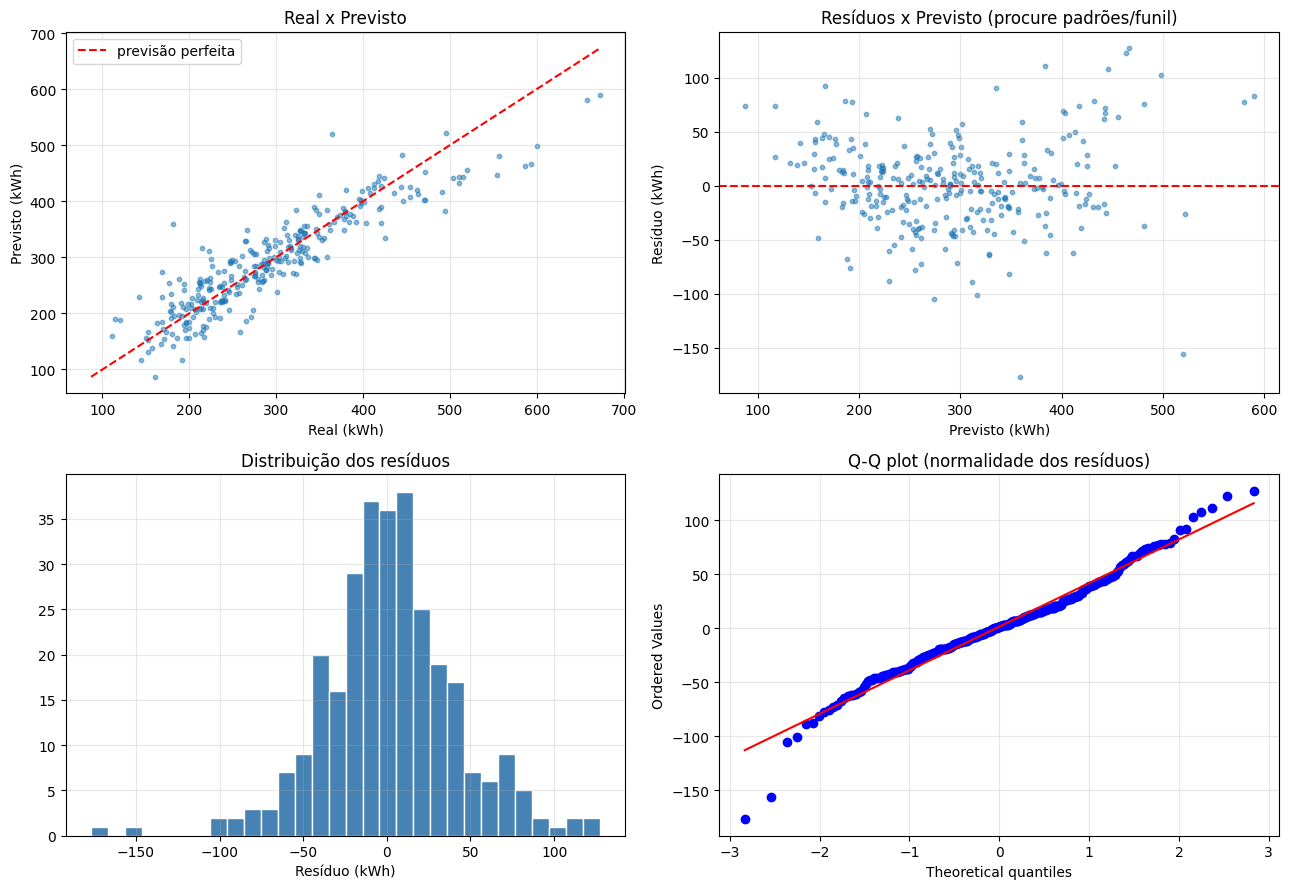

Resíduo médio (viés): 1.55 kWh | desvio: 40.62 kWh | assimetria: -0.16


In [37]:
residuos = y_test.values - y_pred_lr_test

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

lim = [min(y_test.min(), y_pred_lr_test.min()), max(y_test.max(), y_pred_lr_test.max())]
axes[0, 0].scatter(y_test, y_pred_lr_test, s=10, alpha=0.5)
axes[0, 0].plot(lim, lim, "r--", label="previsão perfeita")
axes[0, 0].set_xlabel("Real (kWh)"); axes[0, 0].set_ylabel("Previsto (kWh)")
axes[0, 0].set_title("Real x Previsto"); axes[0, 0].legend()

axes[0, 1].scatter(y_pred_lr_test, residuos, s=10, alpha=0.5)
axes[0, 1].axhline(0, color="r", ls="--")
axes[0, 1].set_xlabel("Previsto (kWh)"); axes[0, 1].set_ylabel("Resíduo (kWh)")
axes[0, 1].set_title("Resíduos x Previsto (procure padrões/funil)")

axes[1, 0].hist(residuos, bins=30, color="steelblue", edgecolor="white")
axes[1, 0].set_title("Distribuição dos resíduos"); axes[1, 0].set_xlabel("Resíduo (kWh)")

stats.probplot(residuos, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot (normalidade dos resíduos)")
plt.tight_layout(); plt.show()

print(f"Resíduo médio (viés): {residuos.mean():.2f} kWh | desvio: {residuos.std():.2f} kWh | assimetria: {stats.skew(residuos):.2f}")

### 5.2.6 Overfitting/Underfitting na Regressão Linear
Comparando treino e teste: se as métricas são parecidas, o modelo **não está sobreajustado**. Se ambas são ruins, pode haver **subajuste** (o modelo é simples demais para a estrutura dos dados, por exemplo por ignorar não linearidades).

In [38]:
tr = metricas_lr.query("Conjunto == 'Treino'").iloc[0]
te = metricas_lr.query("Conjunto == 'Teste'").iloc[0]
print(f"RMSE treino = {tr['RMSE']:.2f} | RMSE teste = {te['RMSE']:.2f} | diferença = {te['RMSE'] - tr['RMSE']:.2f} kWh")
print(f"R²   treino = {tr['R²']:.3f} | R²   teste = {te['R²']:.3f}")

RMSE treino = 42.59 | RMSE teste = 40.65 | diferença = -1.95 kWh
R²   treino = 0.822 | R²   teste = 0.828


# Etapa 6 — Baseline 2: Árvore de Decisão para Regressão
**Responsável: Morya**

## 6.1 Teoria
A **Árvore de Decisão para Regressão** (`DecisionTreeRegressor`) divide o espaço das variáveis por **perguntas binárias** (ex.: `area_m2 <= 80?`). Em cada nó escolhe-se a variável e o limiar que **mais reduzem o erro quadrático** (MSE) dos grupos resultantes. Cada **folha** prevê a **média** do alvo das observações que caíram nela.

* **Vantagens:** captura **não linearidades e interações** automaticamente; não exige padronização; interpretável (regras "se-então"); lida com variáveis de escalas diferentes.
* **Limitações:** previsões **constantes por partes** (degraus); **muito propensa a overfitting** se crescer sem limite; instável (pequenas mudanças nos dados mudam a árvore); não extrapola fora da faixa vista no treino.

**Hiperparâmetros de controle de complexidade:** `max_depth` (profundidade máxima), `min_samples_leaf` (mínimo de amostras por folha), `min_samples_split`, `ccp_alpha` (poda).

In [39]:
# Árvore SEM restrições (cresce até decorar o treino) -> exemplo clássico de overfitting
arvore_full = Pipeline([
    ("prep", preprocessor),
    ("reg", DecisionTreeRegressor(random_state=SEED)),
]).fit(X_train, y_train)

rmse_full_tr = np.sqrt(mean_squared_error(y_train, arvore_full.predict(X_train)))
rmse_full_te = np.sqrt(mean_squared_error(y_test, arvore_full.predict(X_test)))
print(f"Árvore sem limites -> RMSE treino: {rmse_full_tr:.2f} | RMSE teste: {rmse_full_te:.2f}")
print(f"Profundidade: {arvore_full.named_steps['reg'].get_depth()} | Folhas: {arvore_full.named_steps['reg'].get_n_leaves()}")

Árvore sem limites -> RMSE treino: 0.00 | RMSE teste: 50.60
Profundidade: 20 | Folhas: 1189


In [40]:
# Escolha dos hiperparâmetros por validação cruzada NO TREINO (o teste continua intocado)
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
pipe_tree = Pipeline([("prep", preprocessor), ("reg", DecisionTreeRegressor(random_state=SEED))])

param_grid = {
    "reg__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "reg__min_samples_leaf": [1, 5, 10, 20],
}
grid = GridSearchCV(pipe_tree, param_grid, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=1)
grid.fit(X_train, y_train)

modelo_tree = grid.best_estimator_        # já reajustado em todo o treino
y_pred_tree_train = modelo_tree.predict(X_train)
y_pred_tree_test = modelo_tree.predict(X_test)

print("Melhores hiperparâmetros:", grid.best_params_)
print(f"RMSE médio na validação cruzada: {-grid.best_score_:.2f} kWh")

Melhores hiperparâmetros: {'reg__max_depth': None, 'reg__min_samples_leaf': 5}
RMSE médio na validação cruzada: 49.71 kWh


## 6.2 Aprofundamento — controlando a complexidade da árvore

### 6.2.1 Curva de complexidade: profundidade x erro
Variamos `max_depth` e comparamos o RMSE de **treino** com o de **validação cruzada** (somente no treino). O ponto onde a validação para de melhorar (ou piora) indica o equilíbrio entre **viés** (árvore rasa demais → *underfitting*) e **variância** (árvore funda demais → *overfitting*).

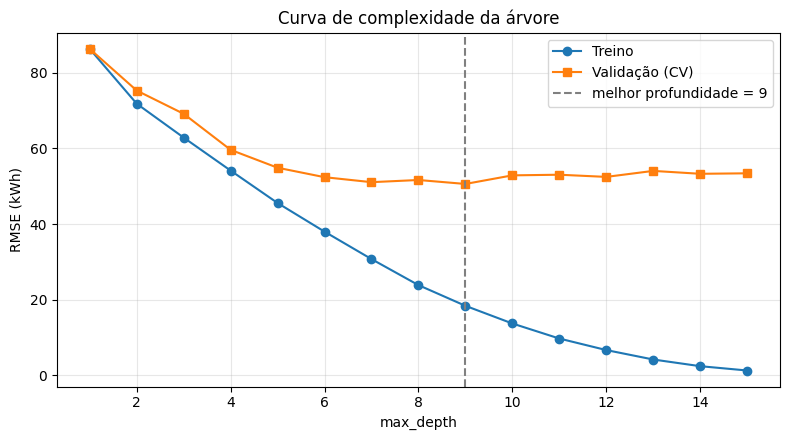

A distância entre as curvas cresce com a profundidade: é o overfitting aumentando.


In [41]:
profundidades = list(range(1, 16))
rmse_tr_cv, rmse_val_cv = [], []
for d in profundidades:
    m = Pipeline([("prep", preprocessor),
                  ("reg", DecisionTreeRegressor(max_depth=d, random_state=SEED))])
    r = cross_validate(m, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error", return_train_score=True)
    rmse_tr_cv.append(-r["train_score"].mean())
    rmse_val_cv.append(-r["test_score"].mean())

melhor_d = profundidades[int(np.argmin(rmse_val_cv))]
fig, ax = plt.subplots()
ax.plot(profundidades, rmse_tr_cv, "o-", label="Treino")
ax.plot(profundidades, rmse_val_cv, "s-", label="Validação (CV)")
ax.axvline(melhor_d, color="gray", ls="--", label=f"melhor profundidade = {melhor_d}")
ax.set_xlabel("max_depth"); ax.set_ylabel("RMSE (kWh)")
ax.set_title("Curva de complexidade da árvore"); ax.legend()
plt.tight_layout(); plt.show()
print("A distância entre as curvas cresce com a profundidade: é o overfitting aumentando.")

### 6.2.2 Resultado do ajuste de hiperparâmetros (`GridSearchCV`)

In [42]:
res = (pd.DataFrame(grid.cv_results_)
       .assign(RMSE_cv=lambda d: -d["mean_test_score"])
       .loc[:, ["param_reg__max_depth", "param_reg__min_samples_leaf", "RMSE_cv"]]
       .sort_values("RMSE_cv").head(8))
res.columns = ["max_depth", "min_samples_leaf", "RMSE (CV)"]
display(res.round(3))

arv = modelo_tree.named_steps["reg"]
print(f"Árvore final -> profundidade: {arv.get_depth()} | folhas: {arv.get_n_leaves()}")

,max_depth,min_samples_leaf,RMSE (CV)
29,None,5,49.71
25,10,5,49.75
21,8,5,50.18
20,8,1,51.66
17,6,5,51.76
30,None,10,51.87
26,10,10,51.88
22,8,10,52.22


Árvore final -> profundidade: 13 | folhas: 189


### 6.2.3 Visualizando a árvore (3 primeiros níveis) e suas regras

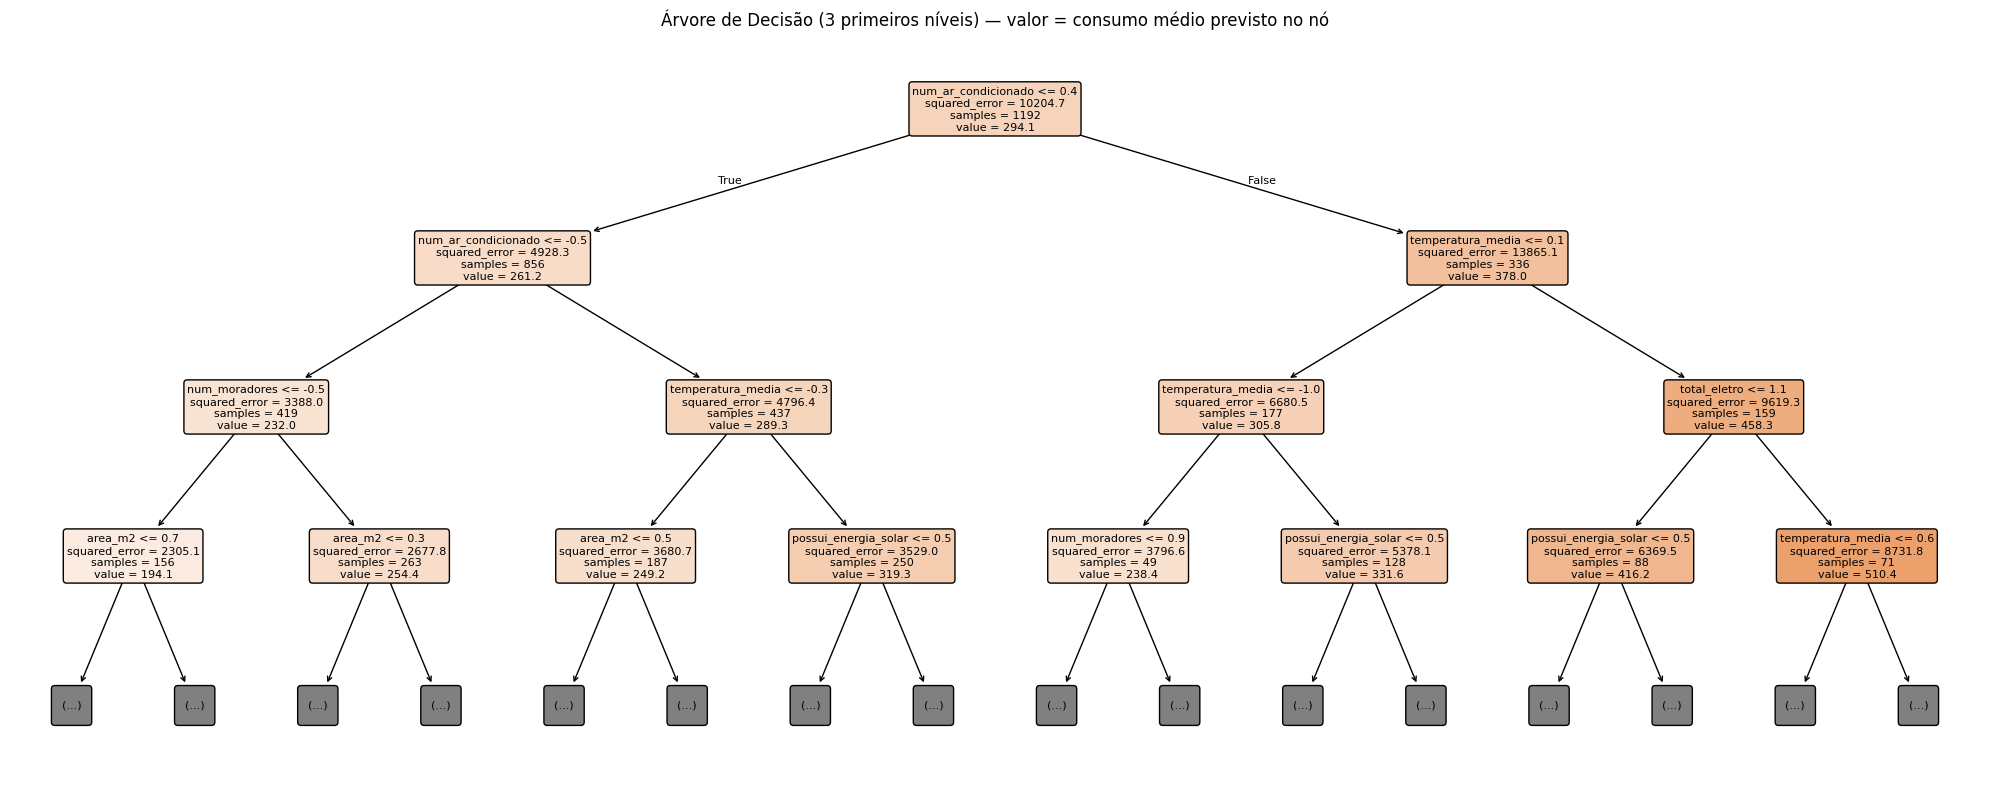

|--- num_ar_condicionado <= 0.39
|   |--- num_ar_condicionado <= -0.53
|   |   |--- num_moradores <= -0.46
|   |   |   |--- truncated branch of depth 10
|   |   |--- num_moradores >  -0.46
|   |   |   |--- truncated branch of depth 11
|   |--- num_ar_condicionado >  -0.53
|   |   |--- temperatura_media <= -0.25
|   |   |   |--- truncated branch of depth 10
|   |   |--- temperatura_media >  -0.25
|   |   |   |--- truncated branch of depth 11
|--- num_ar_condicionado >  0.39
|   |--- temperatura_media <= 0.06
|   |   |--- temperatura_media <= -1.03
|   |   |   |--- truncated branch of depth 7
|   |   |--- temperatura_media >  -1.03
|   |   |   |--- truncated branch of depth 8
|   |--- temperatura_media >  0.06
|   |   |--- total_eletro <= 1.09
|   |   |   |--- truncated branch of depth 8
|   |   |--- total_eletro >  1.09
|   |   |   |--- truncated branch of depth 6



In [43]:
nomes_tree = [n.split("__", 1)[1] for n in modelo_tree.named_steps["prep"].get_feature_names_out()]

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(arv, max_depth=3, feature_names=nomes_tree, filled=True, rounded=True, fontsize=8, ax=ax, precision=1)
ax.set_title("Árvore de Decisão (3 primeiros níveis) — valor = consumo médio previsto no nó")
plt.tight_layout(); plt.show()

print(export_text(arv, feature_names=nomes_tree, max_depth=2))

> **Atenção:** as variáveis numéricas passam pelo `StandardScaler`, então os limiares aparecem em **desvios-padrão** (ex.: `area_m2 <= 0.35` = pouco acima da área média). Isso não altera as divisões escolhidas pela árvore.

### 6.2.4 Importância das variáveis
A importância mede a **redução total de erro** atribuída a cada variável. Variáveis sem efeito real (ex.: `idade_imovel_anos`) devem ficar com importância próxima de zero.

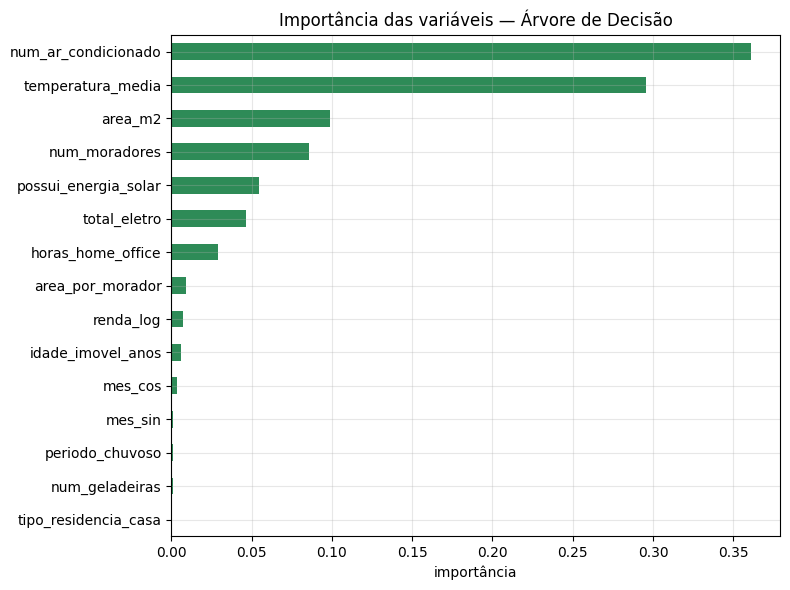

,importância
num_ar_condicionado,0.36
temperatura_media,0.30
area_m2,0.10
num_moradores,0.09
possui_energia_solar,0.05
total_eletro,0.05
horas_home_office,0.03
area_por_morador,0.01


In [44]:
imp = pd.Series(arv.feature_importances_, index=nomes_tree).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
imp.plot.barh(ax=ax, color="seagreen")
ax.set_title("Importância das variáveis — Árvore de Decisão"); ax.set_xlabel("importância")
plt.tight_layout(); plt.show()
display(imp.sort_values(ascending=False).head(8).to_frame("importância").round(4))

### 6.2.5 Comparação: árvore sem limites x árvore ajustada

In [45]:
comp_arv = pd.concat([
    avaliar(arvore_full, X_train, y_train, X_test, y_test, "Árvore sem limites"),
    avaliar(modelo_tree, X_train, y_train, X_test, y_test, "Árvore ajustada"),
])
display(comp_arv.round(3))
print("A árvore sem limites acerta ~100% no treino mas piora no teste (overfitting); a ajustada generaliza melhor.")

,Modelo,Conjunto,MAE,MSE,RMSE,R²
0,Árvore sem limites,Treino,0.00,0.00,0.00,1.00
1,Árvore sem limites,Teste,37.68,"2,560.40",50.60,0.73
0,Árvore ajustada,Treino,19.61,729.42,27.01,0.93
1,Árvore ajustada,Teste,35.03,"2,123.56",46.08,0.78


A árvore sem limites acerta ~100% no treino mas piora no teste (overfitting); a ajustada generaliza melhor.


# Etapa 7 — Métricas da Árvore de Decisão e Gráficos de Erro
**Responsável: Taliciane**

## 7.1 Teoria
Reutilizamos as métricas da Etapa 5 (MAE, MSE, RMSE, R²). Para árvores há pontos de atenção:

* Como as previsões são **médias de folhas**, o gráfico real × previsto mostra **degraus** (poucos valores distintos previstos).
* Árvores tendem a **R² de treino muito alto** quando profundas; a diferença treino × teste é o termômetro do overfitting.
* Métricas globais escondem **onde** o modelo erra; por isso complementamos com **gráficos de erro** e **erro por segmento**.

In [53]:
metricas_tree = avaliar(modelo_tree, X_train, y_train, X_test, y_test, "Árvore de Decisão")
display(metricas_tree.round(3))

,Modelo,Conjunto,MAE,MSE,RMSE,R²
0,Árvore de Decisão,Treino,19.61,729.42,27.01,0.93
1,Árvore de Decisão,Teste,35.03,"2,123.56",46.08,0.78


---
### APROFUNDAMENTO DA ETAPA 7 —
*Métricas da Árvore de Decisão e gráficos de erro*
---

## 7.2 Aprofundamento — análise de erros da Árvore de Decisão

### 7.2.1 Métricas em contexto e sinal de overfitting

In [54]:
media_alvo = y_test.mean()
t_tr = metricas_tree.query("Conjunto == 'Treino'").iloc[0]
t_te = metricas_tree.query("Conjunto == 'Teste'").iloc[0]

print(f"MAE  teste = {t_te['MAE']:.1f} kWh (~{t_te['MAE']/media_alvo:.1%} do consumo médio)")
print(f"RMSE teste = {t_te['RMSE']:.1f} kWh (~{t_te['RMSE']/media_alvo:.1%} do consumo médio)")
print(f"RMSE/MAE (teste) = {t_te['RMSE']/t_te['MAE']:.2f}  (quanto maior, mais erros grandes pesam)")
print(f"Gap treino x teste: RMSE {t_te['RMSE'] - t_tr['RMSE']:+.2f} kWh | R² {t_te['R²'] - t_tr['R²']:+.3f}")

MAE  teste = 35.0 kWh (~12.0% do consumo médio)
RMSE teste = 46.1 kWh (~15.7% do consumo médio)
RMSE/MAE (teste) = 1.32  (quanto maior, mais erros grandes pesam)
Gap treino x teste: RMSE +19.07 kWh | R² -0.150


### 7.2.2 Real x Previsto e Resíduos

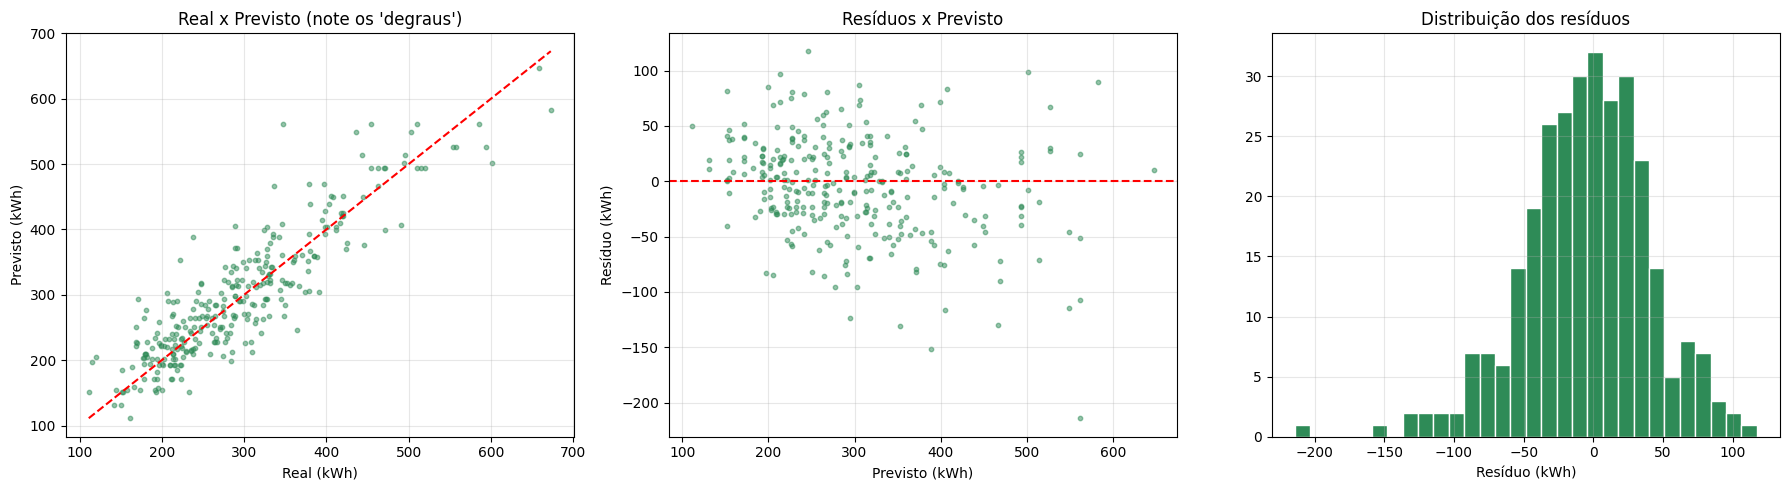

Resíduo médio (viés): -5.33 kWh | desvio: 45.77 kWh
Valores distintos previstos: 141 (a árvore tem 189 folhas)


In [55]:
res_tree = y_test.values - y_pred_tree_test

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
lim = [y_test.min(), y_test.max()]
axes[0].scatter(y_test, y_pred_tree_test, s=10, alpha=0.5, color="seagreen")
axes[0].plot(lim, lim, "r--"); axes[0].set_xlabel("Real (kWh)"); axes[0].set_ylabel("Previsto (kWh)")
axes[0].set_title("Real x Previsto (note os 'degraus')")

axes[1].scatter(y_pred_tree_test, res_tree, s=10, alpha=0.5, color="seagreen")
axes[1].axhline(0, color="r", ls="--"); axes[1].set_xlabel("Previsto (kWh)"); axes[1].set_ylabel("Resíduo (kWh)")
axes[1].set_title("Resíduos x Previsto")

axes[2].hist(res_tree, bins=30, color="seagreen", edgecolor="white")
axes[2].set_title("Distribuição dos resíduos"); axes[2].set_xlabel("Resíduo (kWh)")
plt.tight_layout(); plt.show()

print(f"Resíduo médio (viés): {res_tree.mean():.2f} kWh | desvio: {res_tree.std():.2f} kWh")
print(f"Valores distintos previstos: {len(np.unique(y_pred_tree_test))} (a árvore tem {modelo_tree.named_steps['reg'].get_n_leaves()} folhas)")

### 7.2.3 Em que situações o modelo erra mais?
Quebramos o **erro absoluto** por faixa de consumo, por mês e por tipo de residência.

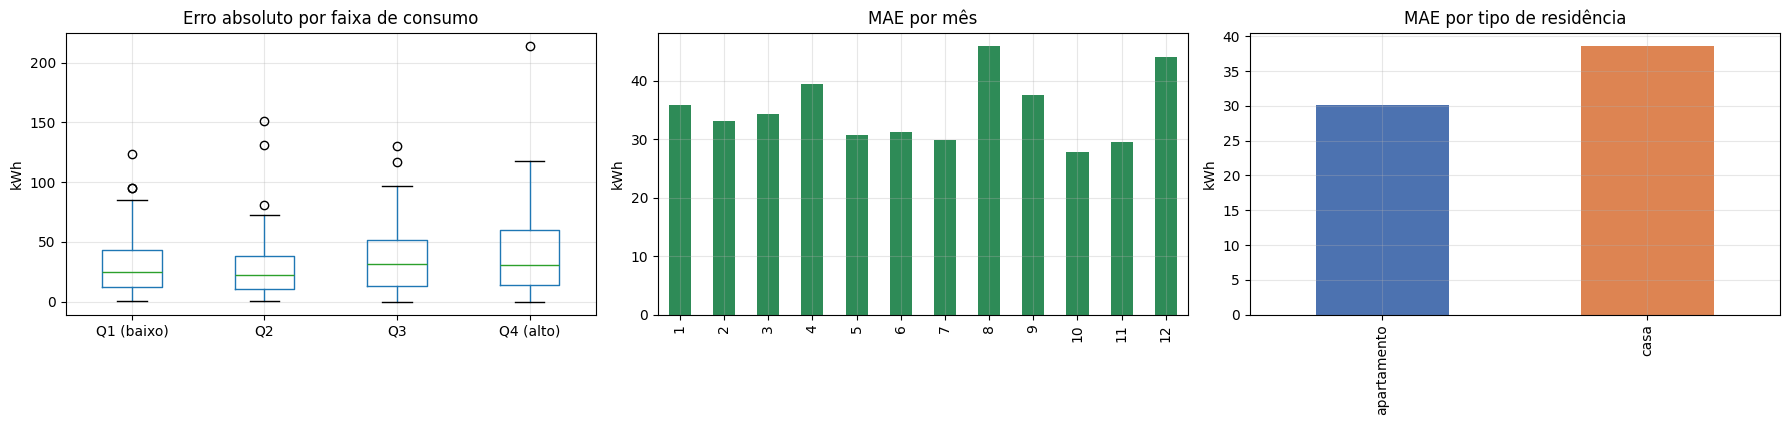

In [56]:
diag = X_test.copy()
diag["real"] = y_test.values
diag["previsto"] = y_pred_tree_test
diag["erro_abs"] = np.abs(diag["real"] - diag["previsto"])
diag["faixa_consumo"] = pd.qcut(diag["real"], 4, labels=["Q1 (baixo)", "Q2", "Q3", "Q4 (alto)"])
diag["mes"] = df_fe.loc[diag.index, "mes"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
diag.boxplot(column="erro_abs", by="faixa_consumo", ax=axes[0]); axes[0].set_title("Erro absoluto por faixa de consumo")
diag.groupby("mes")["erro_abs"].mean().plot.bar(ax=axes[1], color="seagreen"); axes[1].set_title("MAE por mês")
diag.groupby("tipo_residencia")["erro_abs"].mean().plot.bar(ax=axes[2], color=["#4c72b0", "#dd8452"]); axes[2].set_title("MAE por tipo de residência")
for ax in axes: ax.set_xlabel(""); ax.set_ylabel("kWh")
plt.suptitle(""); plt.tight_layout(); plt.show()

### 7.2.4 Os maiores erros
Inspecionar os piores casos ajuda a entender limitações (ex.: combinações raras de características).

In [57]:
cols_show = ["real", "previsto", "erro_abs", "area_m2", "num_moradores", "num_ar_condicionado",
             "temperatura_media", "possui_energia_solar"]
display(diag.sort_values("erro_abs", ascending=False)[cols_show].head(10).round(1))

pct = (diag["erro_abs"] <= 0.10 * diag["real"]).mean()
print(f"\nPrevisões com erro de até 10% do valor real: {pct:.1%}")

,real,previsto,erro_abs,area_m2,num_moradores,num_ar_condicionado,temperatura_media,possui_energia_solar
778,347.20,561.50,214.30,50.30,1,3,30.30,1
1077,237.50,389.00,151.60,123.50,5,1,22.60,1
503,222.40,353.20,130.80,61.80,2,3,24.60,0
370,336.20,466.20,130.00,25.00,1,2,28.80,0
213,170.50,294.30,123.80,124.10,2,1,22.30,1
145,363.80,246.30,117.50,147.30,7,5,24.90,1
1378,288.40,405.20,116.80,25.00,4,3,25.40,0
985,435.50,549.60,114.10,57.40,5,2,29.40,0
598,454.40,561.50,107.10,116.60,2,3,28.50,0
595,600.80,502.00,98.80,59.60,6,3,31.40,0



Previsões com erro de até 10% do valor real: 49.2%


### 7.2.5 Distribuição acumulada do erro
Responde: "em quantos % dos casos o erro é menor que X kWh?"

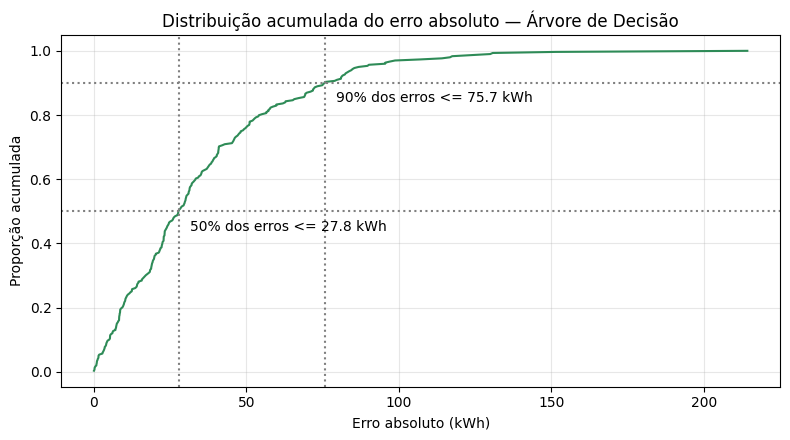

In [58]:
erros_ord = np.sort(diag["erro_abs"].values)
acum = np.arange(1, len(erros_ord) + 1) / len(erros_ord)
fig, ax = plt.subplots()
ax.plot(erros_ord, acum, color="seagreen")
for q in [0.5, 0.9]:
    v = np.quantile(erros_ord, q)
    ax.axhline(q, color="gray", ls=":"); ax.axvline(v, color="gray", ls=":")
    ax.annotate(f"{q:.0%} dos erros <= {v:.1f} kWh", (v, q), textcoords="offset points", xytext=(8, -14))
ax.set_xlabel("Erro absoluto (kWh)"); ax.set_ylabel("Proporção acumulada")
ax.set_title("Distribuição acumulada do erro absoluto — Árvore de Decisão")
plt.tight_layout(); plt.show()